## Backtest resutls and visualization

Backtest resutls for strategies saved in the `results/run` directory. The notebook visualizes out of sample returns for the different strategies and summarizes the following metrics: 
- Expected shortfall at 80% confidence level (ES80)
- Annualized volatility (Vol)
- Sharpe ratio (SR)
- Soritno ratio (SOR)
- Maximum drawdown (MD)
- Expected shortfall ratio (ESR)
- Average asset turnover (AAT)
- Average currency turnover (ACT)

In [31]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

RUNS_DIR = "runs"
OPTIMIZER_RUN_DIRS = [f"{RUNS_DIR}/{d}" for d in os.listdir(RUNS_DIR) if os.path.isdir(f"{RUNS_DIR}/{d}")]
RUN_TO_UNIVERSE_SIZE = {"1":10, "2":50, "3":100}

# Expected shortfall optimization

### Metrics summary table for expected shortfall optimization backtested on increasing unvierses sizes

In [32]:
es_metrics = {}

for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  # only first 3 runs for each universe size
        json_path = f"{run_dir}/{run_num}/metrics.json"
        with open(json_path) as f:
            es_metrics[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = json.load(f)

# Construct and visualize a table of 3 panels for the 3 different universe sizes
es_metrics = pd.DataFrame.from_dict(es_metrics, orient="index")
columns = ["ES80", "Vol", "MD", "SR", "SOR", "ESR", "AAT", "ACT"]
es_metrics.columns = columns

es_metrics.index = es_metrics.index.set_levels(
    es_metrics.index.levels[1].astype(int), level=1
)
sizes = sorted(es_metrics.index.get_level_values(1).unique()) 
panels = {size: es_metrics.xs(size, level=1) for size in sizes}
panels = {size: es_metrics.xs(size, level=1).T for size in sizes}
for size in sizes:
    panels[size].columns = [c.split('/')[-1] for c in panels[size].columns]

strategy_order = ['equal_weight_optimizer', 'reg_es_asset_full', 'reg_es_asset_zero', "es_curr_overlay", "reg_es_curr_overlay", "es_joint", "reg_es_joint"] 
panels = {size: panels[size][strategy_order] for size in sizes}

In [33]:
for size in sizes:
    print(f"Universe size: {size}")
    display(panels[size].round(4))

Universe size: 10


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,1.1540,0.9073,1.1067,0.6905,0.9073,0.6697,0.9073
Vol,13.9564,11.0137,13.5930,8.1764,11.0137,7.9727,11.0138
MD,54.7697,48.1830,56.6093,29.3094,48.1830,28.3079,48.1831
SR,0.1271,0.1459,0.1839,0.0752,0.1459,0.0779,0.1459
SOR,0.1739,0.1965,0.2522,0.1018,0.1965,0.1063,0.1965
ESR,0.0968,0.1116,0.1423,0.0561,0.1116,0.0584,0.1116
AAT,0.1493,0.1482,0.1512,0.6496,0.1482,0.6346,0.1482
ACT,0.9182,0.8917,0.0000,2.3890,0.8917,2.9796,0.8917


Universe size: 50


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,1.0399,0.5674,0.8360,0.4425,0.5674,0.4347,0.5674
Vol,12.5001,7.1745,10.3174,5.6760,7.1745,5.5263,7.1745
MD,55.7457,45.4151,53.4859,38.5860,45.4151,38.8368,45.4152
SR,0.3270,0.5223,0.4710,0.5570,0.5223,0.5335,0.5223
SOR,0.4419,0.6759,0.6380,0.7538,0.6759,0.7271,0.6759
ESR,0.2476,0.4160,0.3662,0.4501,0.4160,0.4273,0.4160
AAT,0.1360,0.1508,0.1579,0.8902,0.1508,0.8926,0.1508
ACT,0.9156,0.9141,0.0000,0.9681,0.9141,1.6734,0.9141


Universe size: 100


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,0.9717,0.4446,0.7391,0.3481,0.4446,0.3476,0.4446
Vol,11.6638,5.7823,9.1446,4.5684,5.7823,4.5463,5.7823
MD,56.2640,45.4842,52.1050,31.3179,45.4842,30.4556,45.4842
SR,0.3654,0.7582,0.5486,0.7183,0.7582,0.7561,0.7582
SOR,0.4889,0.9549,0.7418,0.9513,0.9549,1.0058,0.9549
ESR,0.2763,0.6212,0.4276,0.5937,0.6212,0.6229,0.6212
AAT,0.1385,0.1622,0.1775,0.9459,0.1622,0.9574,0.1622
ACT,0.9084,0.9363,0.0000,0.9689,0.9363,1.4313,0.9363


### Cumulative returns of expected shortfall optimization backtested on increasing unvierses sizes

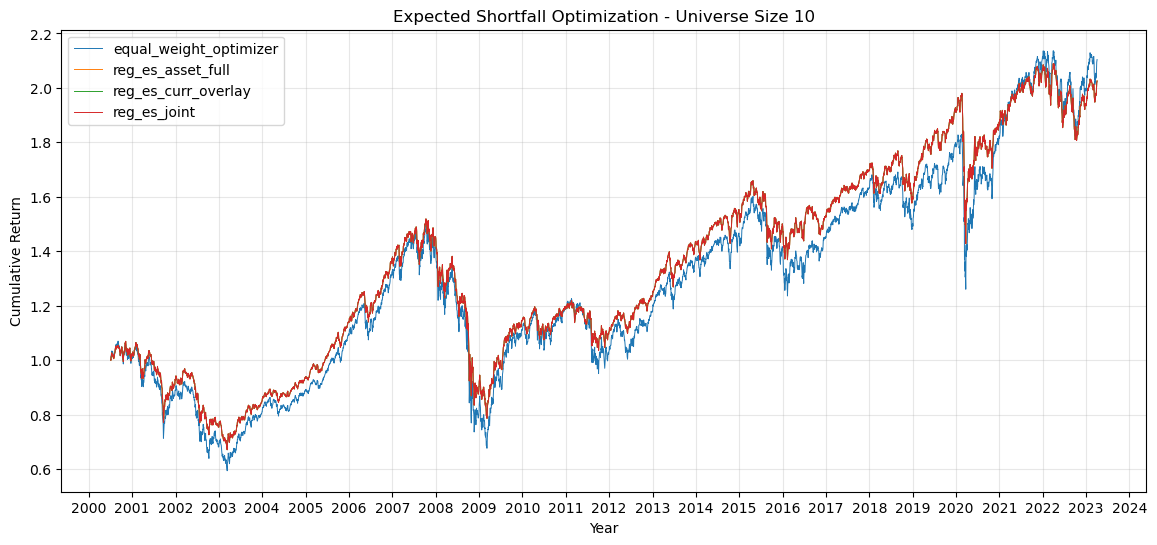

In [34]:
es_returns = {}
for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  
        json_path = f"{run_dir}/{run_num}/oos_returns.csv" 
        es_returns[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = pd.read_csv(json_path, index_col=0, parse_dates=True)
strategies = ['equal_weight_optimizer', 'reg_es_asset_full', "reg_es_curr_overlay", "reg_es_joint"] 


# Expected shortfall optimization cumulative returns plot, universe size 10
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_10 = (1 + es_returns[(f"runs/{strategy}", 10)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_10.index, es_cumulative_returns_10, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 10")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


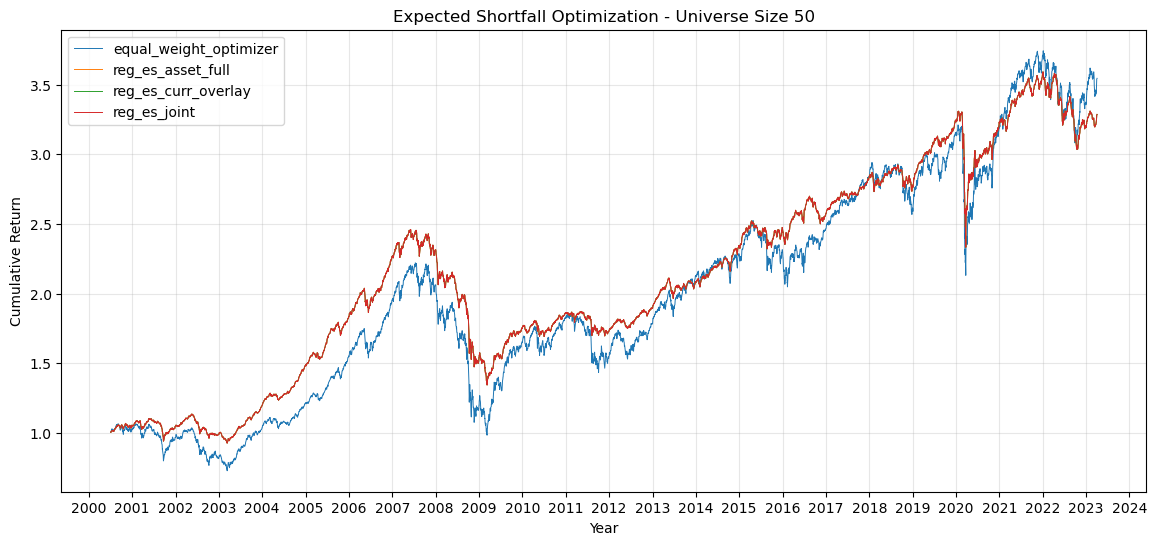

In [35]:
# Expected shortfall optimization cumulative returns plot, universe size 50
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_50 = (1 + es_returns[(f"runs/{strategy}", 50)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_50.index, es_cumulative_returns_50, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 50")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

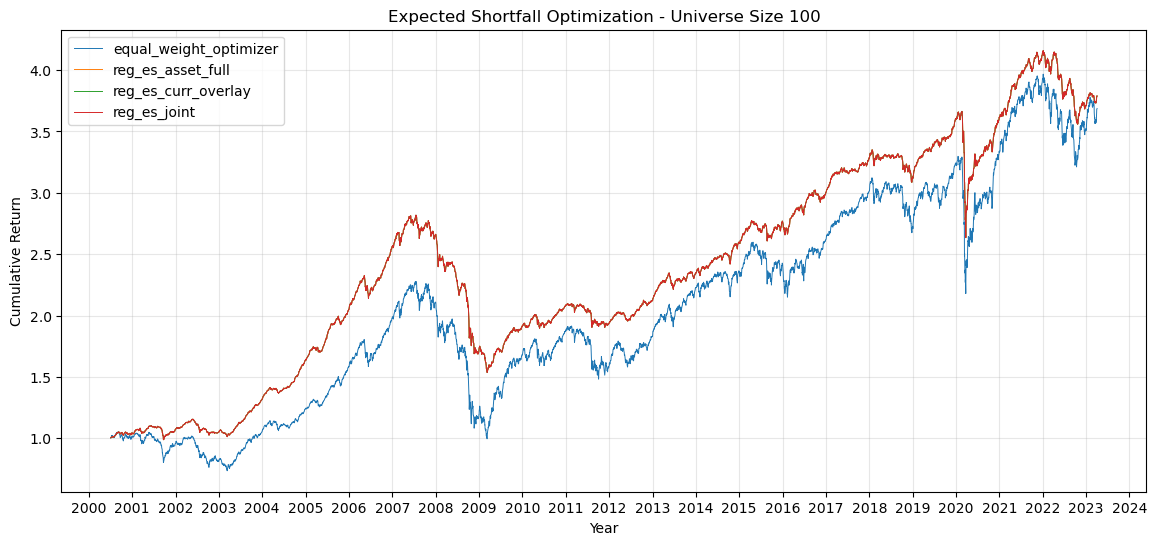

In [36]:
# Expected shortfall optimization cumulative returns plot, universe size 100
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_100 = (1 + es_returns[(f"runs/{strategy}", 100)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_100.index, es_cumulative_returns_100, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 100")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

# Mean-variance strategies

### Metrics summary table for mean-variance strategies backtested on increasing universe sizes

In [37]:
mv_metrics = {}

for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  # only first 3 runs for each universe size
        json_path = f"{run_dir}/{run_num}/metrics.json"
        with open(json_path) as f:
            mv_metrics[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = json.load(f)

# Construct and visualize a table of 3 panels for the 3 different universe sizes
mv_metrics = pd.DataFrame.from_dict(mv_metrics, orient="index")
columns = ["ES80", "Vol", "MD", "SR", "SOR", "ESR", "AAT", "ACT"]
mv_metrics.columns = columns

mv_metrics.index = mv_metrics.index.set_levels(
    mv_metrics.index.levels[1].astype(int), level=1
)
sizes = sorted(mv_metrics.index.get_level_values(1).unique()) 
panels = {size: mv_metrics.xs(size, level=1) for size in sizes}
panels = {size: mv_metrics.xs(size, level=1).T for size in sizes}
for size in sizes:
    panels[size].columns = [c.split('/')[-1] for c in panels[size].columns]

strategy_order = ['equal_weight_optimizer', "reg_mv_asset_full"] 
panels = {size: panels[size][strategy_order] for size in sizes}

In [38]:
for size in sizes:
    print(f"Universe size: {size}")
    display(panels[size].round(4))

Universe size: 10


,equal_weight_optimizer,reg_mv_asset_full
ES80,1.1540,1.1499
Vol,13.9564,13.8971
MD,54.7697,54.6781
SR,0.1271,0.1249
SOR,0.1739,0.1709
ESR,0.0968,0.0951
AAT,0.1493,0.1469
ACT,0.9182,0.9167


Universe size: 50


,equal_weight_optimizer,reg_mv_asset_full
ES80,1.0399,1.0273
Vol,12.5001,12.3054
MD,55.7457,55.4529
SR,0.3270,0.3143
SOR,0.4419,0.4239
ESR,0.2476,0.2372
AAT,0.1360,0.1261
ACT,0.9156,0.9117


Universe size: 100


,equal_weight_optimizer,reg_mv_asset_full
ES80,0.9717,0.9612
Vol,11.6638,11.4821
MD,56.2640,56.3204
SR,0.3654,0.3502
SOR,0.4889,0.4674
ESR,0.2763,0.2635
AAT,0.1385,0.1261
ACT,0.9084,0.9010
